### Pré-processamentos dos dados

Este notebook aplica filtros temporais e realiza a comparação da visualização dados antes e depois da aplicação dos filtros.

In [1]:
# realizando o carregamento dos dados MNE

import mne

# Carregando os dados do arquivo .fif de epochs
epochs = mne.read_epochs('s08-epo.fif')

Reading /home/rhubner/tutoriais/SomeFeatures/s08-epo.fif ...
Isotrak not found
    Found the data of interest:
        t =       0.00 ...     124.00 ms
        0 CTF compensation matrices available
Not setting metadata
3764 matching events found
No baseline correction applied
0 projection items activated


In [2]:
# dinamizando parâmetros

target = 'hit'
epo = 10

In [3]:
import matplotlib.pyplot as plt

def plots_evoked(evoked_data):
    '''
    Plota os dados evocados para cada canal.

    Parâmetros:
    evoked_data (mne.Evoked): Objeto contendo os dados evocados.
    '''
    
    # extrai os dados (canais x tempos) e o vetor de tempo
    # evoked_data.get_data() retorna um array 3D: (epochs, channels, times)
    # selecionando apenas 1 época, pegamos o índice [0] para torná-lo 2D
    data = evoked_data.get_data()[0]
    times = evoked_data.times
    ch_names = evoked_data.ch_names

    # configura a grade de 8 blocos (4 linhas x 2 colunas)
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
    axes = axes.flatten()

    for i, channel_name in enumerate(ch_names):
        ax = axes[i]

        ax.plot(times, data[i], label=channel_name, color="red")
        ax.set_title(f"Canal: {channel_name}")
        ax.grid(True, linestyle="--", alpha=0.5)

        # Rótulo do eixo Y apenas na coluna da esquerda
        if i % 2 == 0:
            ax.set_ylabel("Amplitude")

        # Rótulo do eixo X apenas na última linha
        if i >= 6:
            ax.set_xlabel("Tempo (s)")

    # Ajusta o layout para evitar sobreposições
    plt.tight_layout()
    plt.suptitle("Único Evento ('hit') - 8 Canais Isolados", y=1.02, fontsize=14)
    plt.show()

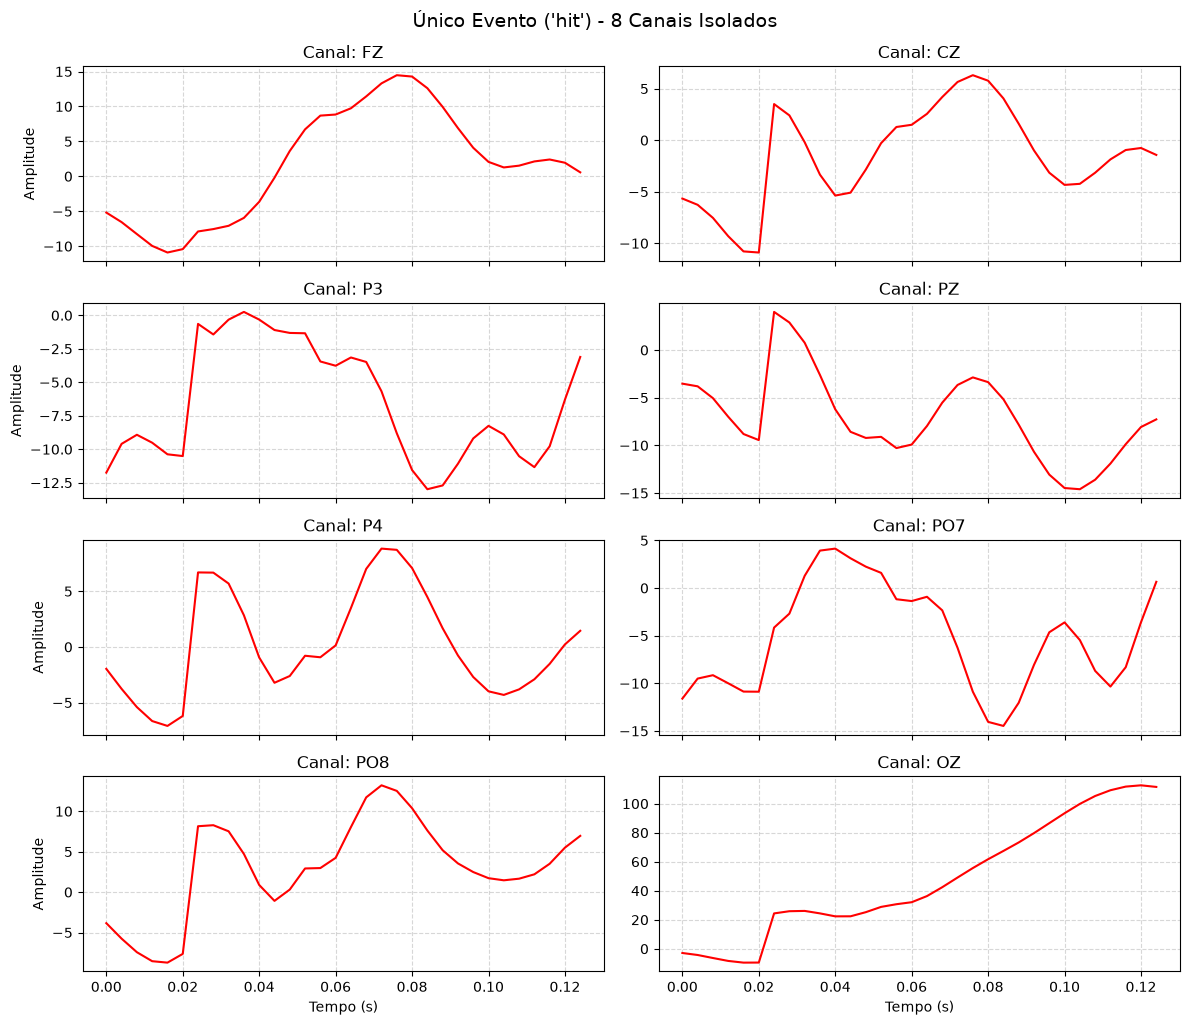

In [4]:
# obtendo 1 'hit' para o plot
plots_evoked(epochs[target][epo])

Como os dados obtidos já estão pré-filtrados (0.1 - 30 Hz _bandpass_, 50 Hz _notch_), será demonstrado algumas aplicações de filtros somente como exemplos de aplicação.

Setting up band-pass filter from 1 - 30 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 16 (effective, after forward-backward)
- Cutoffs at 1.00, 30.00 Hz: -6.02, -6.02 dB



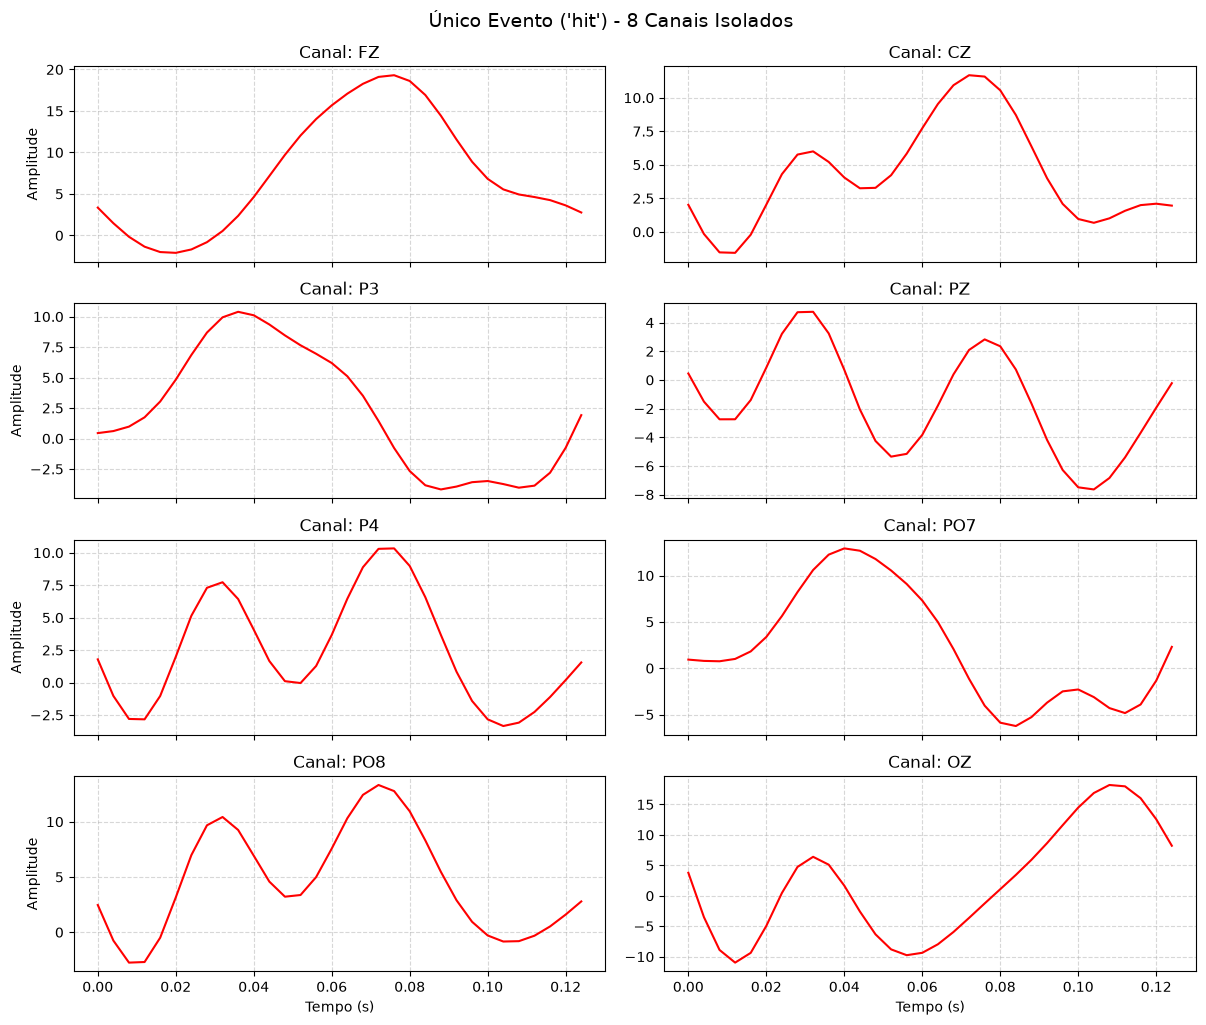

In [18]:
# dados modificados para máxima e mínima frequência para encontrar a faixa de dados úteis
low_freq = 1.0
high_freq = 30.0

epochs_filtradas = epochs.copy().filter(l_freq=low_freq, h_freq=high_freq, method='iir')
# epochs_filtradas = epochs.copy()
plots_evoked(epochs_filtradas[target][epo])

In [19]:
# salvando o objeto EpochsArray filtrado em um arquivo .fif
epochs_filtradas.save('s08-epo.fif', overwrite=True)

Overwriting existing file.
Overwriting existing file.
Overwriting existing file.


[PosixPath('/home/rhubner/tutoriais/SomeFeatures/s08-epo.fif')]